# Шаг 3. Смысл как вектор

В бонусе сессии 5 CLIP переводил картинку и текст в векторы, и близость векторов говорила, подходит ли подпись к картинке.
Здесь то же самое, но только для текста: **фраза → вектор из 312 чисел** (класс `Embedder` в `common.py`).

Как получается вектор: фраза режется на токены, BERT выдаёт вектор для каждого токена, а мы берём вектор служебного токена `[CLS]`
и делаем его длину равной 1. rubert-tiny2 специально дообучали так, чтобы фразы с одинаковым смыслом
(например, переводы одного предложения на разные языки) получали близкие векторы `[CLS]`.

**Косинусная близость** двух векторов длины 1 — это их скалярное произведение:
1 — смотрят в одну сторону (одинаковый смысл), около 0 — не связаны.

In [1]:
# Настройка для Google Colab. На своём компьютере эта ячейка ничего не делает.
# В Colab нужна папка machine_vision на Google Диске (в ней session05 и session06).
import os
import sys

try:
    from google.colab import drive
except ImportError:
    drive = None

if drive:
    drive.mount("/content/drive")
    COLAB_ROOT = "/content/drive/MyDrive/machine_vision"
    os.chdir(f"{COLAB_ROOT}/session06")  # здесь лежит common.py; модели скачаются в machine_vision/data/hf
    sys.path.insert(0, os.getcwd())
    !pip install -q transformers

In [2]:
import matplotlib.pyplot as plt
import torch

from common import Embedder, show

embed = Embedder()
v = embed("Кошка спит на диване.")
print("вектор фразы:", tuple(v.shape), "первые 6 чисел:", [round(x, 3) for x in v[0, :6].tolist()])
print("длина вектора:", round(v.norm().item(), 3))

вектор фразы: (1, 312) первые 6 чисел: [-0.024, -0.038, 0.007, -0.033, -0.015, 0.02]
длина вектора: 1.0


## 1. Близость фраз

Перед запуском угадайте: какие пары фраз модель сочтёт близкими?

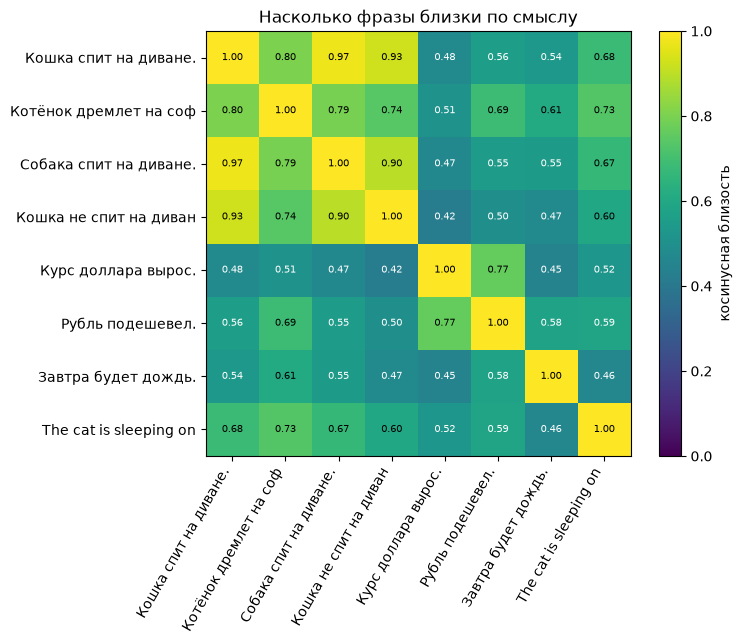

In [3]:
phrases = [
    "Кошка спит на диване.",
    "Котёнок дремлет на софе.",
    "Собака спит на диване.",
    "Кошка не спит на диване.",
    "Курс доллара вырос.",
    "Рубль подешевел.",
    "Завтра будет дождь.",
    "The cat is sleeping on the sofa.",
]
vectors = embed(phrases)
sim = vectors @ vectors.T                     # все попарные косинусные близости сразу

plt.figure(figsize=(8, 6.5))
plt.imshow(sim, cmap="viridis", vmin=0, vmax=1)
plt.colorbar(label="косинусная близость")
plt.xticks(range(len(phrases)), [p[:22] for p in phrases], rotation=60, ha="right")
plt.yticks(range(len(phrases)), [p[:22] for p in phrases])
for i in range(len(phrases)):
    for j in range(len(phrases)):
        plt.text(j, i, f"{sim[i, j]:.2f}", ha="center", va="center", fontsize=7,
                 color="black" if sim[i, j] > 0.6 else "white")
plt.title("Насколько фразы близки по смыслу")
plt.tight_layout()
plt.savefig("similarity.png", dpi=100)
show()

**Что видно:**
- «Кошка спит на диване» и «Котёнок дремлет на софе» близки, хотя общих слов почти нет — модель знает синонимы;
- английская фраза близка к русской: модель учили сближать переводы;
- «Курс доллара вырос» и «Рубль подешевел» близки — это одна тема (и, по сути, одно событие);
- даже совсем разные фразы получают близость 0.45–0.55, а не 0: у этой модели важны не сами числа, а **какая фраза ближе других**;
- **но:** «Кошка спит» и «Кошка **не** спит» почти одинаковы! Вектор фразы ловит тему, а маленькое «не» почти теряется.
  Это то же слабое место, что у модели тона в шаге 2.

## 2. Карта смыслов

Векторы из 312 чисел нельзя нарисовать. Сожмём их до двух чисел методом **PCA** (метод главных компонент):
он находит два направления, вдоль которых точки больше всего различаются, и проецирует на них.
Это как тень от трёхмерного предмета на стене — что-то теряется, но общая форма видна.

Возьмём 40 фраз на четыре темы. Модель **не знает**, какая фраза к какой теме относится, — цвет мы добавим сами, после.

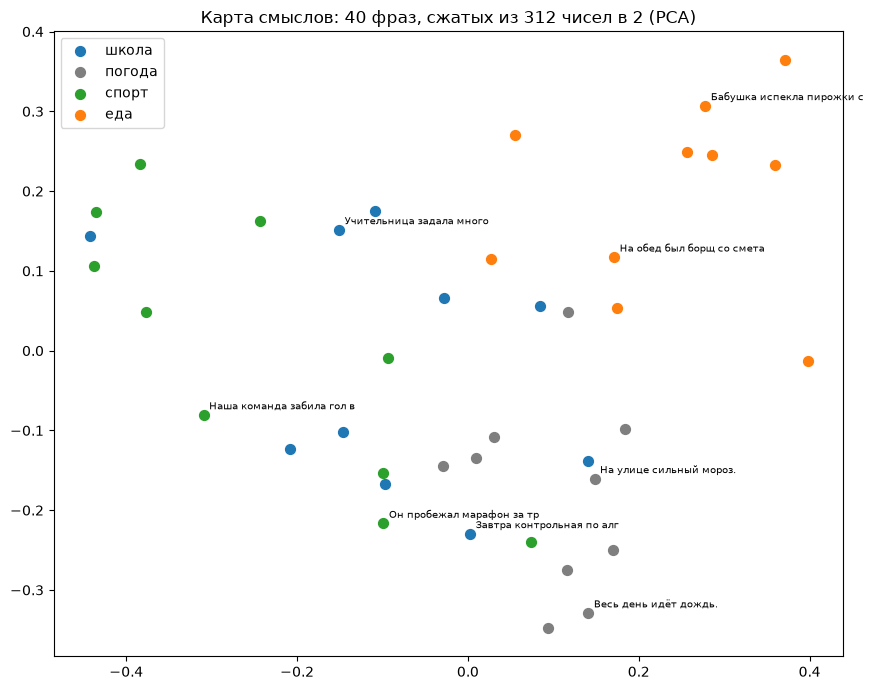

In [4]:
topics = {
    "школа": ["Завтра контрольная по алгебре.", "Учительница задала много домашки.", "Я получил пятёрку за сочинение.",
              "На перемене мы играли в коридоре.", "Директор собрал всех в актовом зале.", "Опять забыл дневник дома.",
              "Звонок прозвенел, урок начался.", "В пятницу у нас лабораторная по химии.", "Классный руководитель позвонил маме.",
              "Нужно выучить стихотворение к понедельнику."],
    "погода": ["На улице сильный мороз.", "Весь день идёт дождь.", "Синоптики обещают солнце.", "Ветер срывает листья с деревьев.",
               "Ночью выпал первый снег.", "Жара стоит уже неделю.", "Над городом сгустились тучи.", "К вечеру ожидается гроза.",
               "Туман такой, что ничего не видно.", "Весна в этом году ранняя."],
    "спорт": ["Наша команда забила гол в последнюю минуту.", "Он пробежал марафон за три часа.", "Тренер похвалил вратаря.",
              "Хоккеисты вышли в финал.", "Я хожу в бассейн три раза в неделю.", "Судья назначил пенальти.",
              "Теннисистка выиграла турнир.", "Болельщики заполнили весь стадион.", "На тренировке мы отжимались сто раз.",
              "Лыжник упал на спуске."],
    "еда": ["Бабушка испекла пирожки с капустой.", "На обед был борщ со сметаной.", "Я люблю пиццу с грибами.",
            "Мама варит вишнёвое варенье.", "В столовой дали макароны с котлетой.", "Этот торт слишком сладкий.",
            "Купи хлеба и молока.", "Шашлык получился сочным.", "Утром я ем овсянку.", "Суп нужно немного посолить."],
}
texts = [t for group in topics.values() for t in group]
labels = [name for name, group in topics.items() for _ in group]
X = embed(texts)

X_centered = X - X.mean(0)
U, S, V = torch.pca_lowrank(X_centered, q=2, center=False)
points = X_centered @ V                       # (40, 2) — «тень» векторов на плоскости

plt.figure(figsize=(9, 7))
for name, color in zip(topics, ["tab:blue", "tab:gray", "tab:green", "tab:orange"]):
    idx = [i for i, lab in enumerate(labels) if lab == name]
    plt.scatter(points[idx, 0], points[idx, 1], color=color, label=name, s=50)
    for i in idx[:2]:
        plt.annotate(texts[i][:25], points[i].tolist(), fontsize=7, xytext=(4, 4), textcoords="offset points")
plt.legend()
plt.title("Карта смыслов: 40 фраз, сжатых из 312 чисел в 2 (PCA)")
plt.tight_layout()
plt.savefig("meaning_map.png", dpi=100)
show()

Еда, погода и спорт собрались в облака, хотя модели никто не говорил про темы. Это и есть «понимание» в смысле нейросети:
похожее по смыслу оказывается рядом. Школьные фразы разбросаны сильнее — они очень разные по содержанию
(контрольная, перемена, звонок маме). Облака перекрываются ещё и потому, что PCA показывает только 2 направления из 312:
в «тени» точки могут наложиться, хотя в полном пространстве они далеко друг от друга.

В шаге 4 мы научим простой классификатор различать такие облака — и получим определитель жанра.

## 3. Поиск по смыслу

Обычный поиск ищет **слова**. Поиск по смыслу ищет **близкие векторы**: запрос → вектор → самые близкие векторы из базы.
Так устроены поиск в современных поисковиках, подбор похожих товаров и «память» чат-ботов.

База — 20 вопросов «справочной» школы. Ученик спрашивает своими словами, а мы ищем самый похожий вопрос из базы
(у каждого вопроса в настоящей справочной был бы готовый ответ).

In [5]:
faq = [
    "Во сколько начинается первый урок?", "Где посмотреть расписание уроков?", "Как записаться в кружок робототехники?",
    "Когда начинаются зимние каникулы?", "Где находится школьная библиотека?", "Как получить справку для поликлиники?",
    "Можно ли приносить в школу телефон?", "Сколько стоит обед в столовой?", "Когда будет родительское собрание?",
    "Как перевестись в другой класс?", "Где найти домашнее задание, если болел?", "Что делать, если потерял учебник?",
    "Нужна ли сменная обувь?", "Когда пишут итоговую контрольную по математике?", "Как попасть на школьную олимпиаду?",
    "Работает ли продлёнка в субботу?", "Где взять форму для физкультуры?", "Кому сообщить, если заболел?",
    "Можно ли пересдать двойку?", "Во сколько закрывается школа вечером?",
]
faq_vectors = embed(faq)


def words(s):
    """Слова фразы маленькими буквами, без знаков препинания."""
    for ch in ",.?!—«»":
        s = s.replace(ch, " ")
    return set(s.lower().split())


def search(query, base, base_vectors, k=3):
    scores = (embed(query) @ base_vectors.T)[0]
    best = scores.topk(k)
    print(f"\nЗапрос: «{query}»")
    for s, i in zip(best.values.tolist(), best.indices.tolist()):
        print(f"   {s:.2f}  {base[i]}")
    overlap = [len(words(query) & words(b)) for b in base]       # обычный поиск: число общих слов
    i = max(range(len(base)), key=lambda j: overlap[j])
    print("   поиск по словам:", base[i] if overlap[i] else "ничего не нашёл", f"(общих слов: {overlap[i]})")


for query in ["когда звонок на первый урок", "я забыл кроссовки для физры, что делать",
              "сколько денег нужно на еду в школе", "меня не было неделю, как узнать что задали",
              "хочу участвовать в конкурсе по физике"]:
    search(query, faq, faq_vectors)


Запрос: «когда звонок на первый урок»
   0.79  Во сколько начинается первый урок?
   0.61  Можно ли приносить в школу телефон?
   0.60  Когда будет родительское собрание?
   поиск по словам: Во сколько начинается первый урок? (общих слов: 2)

Запрос: «я забыл кроссовки для физры, что делать»
   0.60  Что делать, если потерял учебник?
   0.59  Где взять форму для физкультуры?
   0.57  Нужна ли сменная обувь?
   поиск по словам: Что делать, если потерял учебник? (общих слов: 2)

Запрос: «сколько денег нужно на еду в школе»
   0.71  Сколько стоит обед в столовой?
   0.65  Как попасть на школьную олимпиаду?
   0.64  Во сколько закрывается школа вечером?
   поиск по словам: Сколько стоит обед в столовой? (общих слов: 2)

Запрос: «меня не было неделю, как узнать что задали»
   0.55  Что делать, если потерял учебник?
   0.55  Где посмотреть расписание уроков?
   0.55  Работает ли продлёнка в субботу?
   поиск по словам: Как записаться в кружок робототехники? (общих слов: 1)

Запрос: «хочу уч

**Разбор:**
- «звонок на первый урок», «деньги на еду», «конкурс по физике» — поиск по смыслу уверенно находит нужный вопрос
  («еда» → «обед в столовой», «конкурс» → «олимпиада»), причём в последнем случае общих слов нет вовсе;
- «кроссовки для физры» — нужный вопрос про форму на втором месте, почти вровень с первым: модель зацепилась за «что делать»;
- «меня не было неделю» — промах: у всех трёх близость 0.55, модель не уверена ни в чём.
  Понять, что «не было неделю» — это «болел», а «что задали» — это «домашнее задание», маленькой модели трудно.

Поиск по словам тоже иногда угадывает — когда слова совпадают буквально, — но легко цепляется за случайные «что» или «как».
Число слева — близость: чем она выше и чем сильнее оторвана от второго места, тем увереннее ответ.
В настоящих поисковиках используют модели для векторов в десятки раз больше rubert-tiny2 — и ошибок у них заметно меньше.

## 4. Трудный случай: иносказание

Теперь база из 30 русских пословиц. Пословица говорит об одном («рыбка из пруда»), а имеет в виду другое («нужно трудиться»).
Сможет ли маленькая модель найти пословицу по её **смыслу**?

In [6]:
proverbs = [
    "Без труда не выловишь и рыбку из пруда.", "Тише едешь — дальше будешь.", "Поспешишь — людей насмешишь.",
    "Не имей сто рублей, а имей сто друзей.", "Друг познаётся в беде.", "Семь раз отмерь, один раз отрежь.",
    "Под лежачий камень вода не течёт.", "Цыплят по осени считают.", "Ученье — свет, а неученье — тьма.",
    "Повторенье — мать ученья.", "Что посеешь, то и пожнёшь.", "Не плюй в колодец — пригодится воды напиться.",
    "Слово не воробей: вылетит — не поймаешь.", "Делу время, потехе час.", "Готовь сани летом, а телегу зимой.",
    "Яблоко от яблони недалеко падает.", "У страха глаза велики.", "Не всё то золото, что блестит.",
    "Встречают по одёжке, провожают по уму.", "Глаза боятся, а руки делают.", "Кто рано встаёт, тому Бог подаёт.",
    "Лучше синица в руках, чем журавль в небе.", "Не откладывай на завтра то, что можно сделать сегодня.",
    "В гостях хорошо, а дома лучше.", "Один в поле не воин.", "Старый друг лучше новых двух.",
    "Береги платье снову, а честь смолоду.", "Аппетит приходит во время еды.", "Сделал дело — гуляй смело.",
    "Терпенье и труд всё перетрут.",
]
proverb_vectors = embed(proverbs)

for query in ["настоящего друга видно, когда у тебя проблемы", "чтобы чего-то добиться, нужно работать",
              "не надо торопиться", "дети похожи на родителей", "внешность обманчива"]:
    search(query, proverbs, proverb_vectors)


Запрос: «настоящего друга видно, когда у тебя проблемы»
   0.67  Друг познаётся в беде.
   0.61  Поспешишь — людей насмешишь.
   0.59  Что посеешь, то и пожнёшь.
   поиск по словам: У страха глаза велики. (общих слов: 1)

Запрос: «чтобы чего-то добиться, нужно работать»
   0.71  Терпенье и труд всё перетрут.
   0.66  Что посеешь, то и пожнёшь.
   0.62  Сделал дело — гуляй смело.
   поиск по словам: ничего не нашёл (общих слов: 0)

Запрос: «не надо торопиться»
   0.68  Делу время, потехе час.
   0.67  Не всё то золото, что блестит.
   0.64  Что посеешь, то и пожнёшь.
   поиск по словам: Без труда не выловишь и рыбку из пруда. (общих слов: 1)

Запрос: «дети похожи на родителей»
   0.60  Повторенье — мать ученья.
   0.55  Глаза боятся, а руки делают.
   0.55  Друг познаётся в беде.
   поиск по словам: Не откладывай на завтра то, что можно сделать сегодня. (общих слов: 1)

Запрос: «внешность обманчива»
   0.71  Поспешишь — людей насмешишь.
   0.64  Друг познаётся в беде.
   0.64  Что посе

Первые два запроса модель угадывает: там в пословице есть прямые слова («друг», «труд»).
Остальные три — промахи. «Внешность обманчива» → «Не всё то золото, что блестит» она не находит: чтобы связать их, нужно понять **переносный смысл**
золота и блеска. Маленькой модели на 29 млн весов это не под силу — большие модели (шаг 7 и дальше) справляются лучше.

Обратите внимание и на числа: близости здесь 0.55–0.7 почти у всех пословиц, разница между первым местом и пятым — маленькая.
Это сигнал «модель не уверена». У rubert-tiny2 даже несвязанные фразы редко получают близость ниже 0.4 —
важны не сами числа, а **какая фраза ближе других**.

## Попробуйте сами

1. Найдите две фразы, похожие по словам, но разные по смыслу («ключ от двери» и «бьющий из-под земли ключ»). Какая у них близость?
2. Найдите две фразы без общих слов с близостью больше 0.8.
3. Добавьте на карту смыслов пятую тему (например, «музыка» или «компьютеры») — 10 своих фраз. Где окажется новое облако?
4. Придумайте запрос, по которому поиск по смыслу находит **неправильную** пословицу. Почему так вышло?
5. Сделайте свою базу для поиска: вопросы из FAQ школы, названия песен, описания фильмов.